# PONTIFICIA UNIVERSIDAD JAVERIANA
## Facultad de Ingeniería — Departamento de Bioingeniería
### Asignatura: Bioinformática (Periodo 2026-2)
### Segundo Parcial Práctico: Genómica Comparativa, Ensamblaje *De Novo* y Filogenética Molecular de *Polaromonas hydrogenivorans*

---

**Integrantes del Grupo:**
1. __________________________________________________________________  
2. __________________________________________________________________  
3. __________________________________________________________________  

**Grupo Asignado:** Grupo 3  
**Organismo de Estudio:** *Polaromonas hydrogenivorans* (Aislado de glaciares y suelos periglaciares)  
**Fecha de Asignación:** Jueves 22 de octubre de 2026  
**Fecha Límite de Entrega:** Jueves 29 de octubre de 2026 (Una semana para su desarrollo)  
**Profesor:** *Juan Sebastián Malagón*  

---


> ⚠️ **RESTRICCIÓN OBLIGATORIA DE INFRAESTRUCTURA Y RECURSOS COMPUTACIONALES:**  
> En virtud de las políticas de uso compartido del servidor de cómputo del curso, **es mandatorio y de estricto cumplimiento** configurar todas las herramientas bioinformáticas y comandos que admitan paralelismo a un **máximo estricto de 2 hilos de procesamiento** (`-t 2`, `--cpus 2` o `-threads 2`).  
> **IMPORTANTE:** El uso de un número superior de hilos sobrecargará los nodos de procesamiento compartidos y afectará el desempeño de los demás grupos de trabajo, constituyendo motivo de penalización directa sobre la calificación del examen.


## Introducción y Contexto Biológico e Industrial

En el parcial anterior se confirmó, a partir de datos genómicos preliminares, la identidad taxonómica del microorganismo psicrófilo polar y oxidante de hidrógeno aislado en los glaciares y suelos periglaciares del **Parque Nacional Natural El Cocuy** (*Polaromonas hydrogenivorans*).

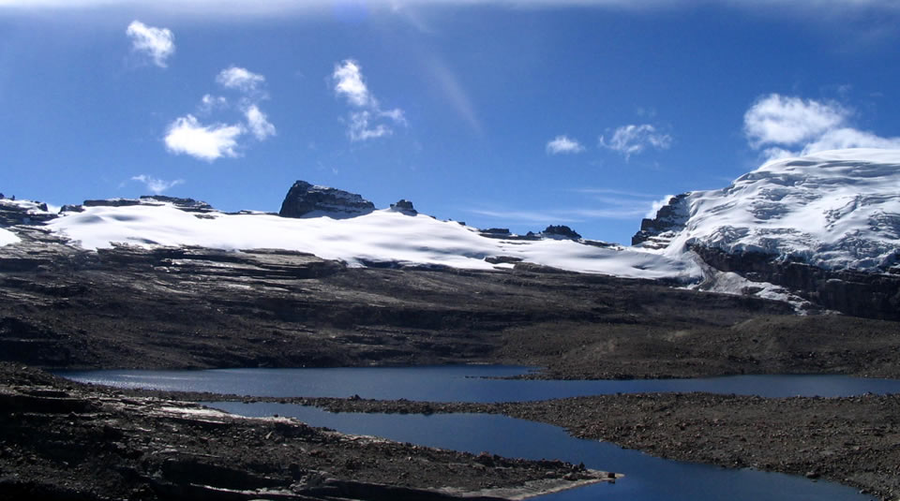

Una **empresa biotecnológica aliada** tiene un alto interés comercial en la explotación y producción de **enzimas activas en frío** (*cold-active enzymes*) e **hidrogenasas**. Estos biocatalizadores representan insumos de altísimo valor agregado con aplicaciones estratégicas en:
1. **Formulación de detergentes ecológicos de baja temperatura:** Enzimas (proteasas, lipasas y amilasas) con alta actividad catalítica específica a temperaturas entre 4 °C y 20 °C, reduciendo el consumo energético de lavado industrial y doméstico.
2. **Industria de alimentos y bebidas:** Biotransformaciones controladas sin desnaturalización térmica, preservando las propiedades organolépticas, nutricionales y reduciendo riesgos de contaminación.
3. **Biorremediación en climas fríos:** Biodegradación eficiente de hidrocarburos y xenobióticos en suelos y efluentes a bajas temperaturas.

No obstante, antes de escalar la producción en biorreactor, la compañía requiere evaluar **alternativas industriales de microorganismos semejantes** pertenecientes al mismo linaje evolutivo que coexistan en el ecosistema o en nichos periglaciares afines, y que presenten eficiencias catalíticas iguales o superiores en condiciones de frío extremo.

Para llevar a cabo este análisis genómico y comparativo, el centro de secuenciación ha entregado las lecturas crudas pareadas de secuenciación de un nuevo aislado del ecosistema y una colección ambiental de referencia con secuencias homólogas.


## Fundamento Teórico: El Marcador Filogenético *gyrB*

En estudios microbiológicos tradicionales, el gen del **ARN ribosomal 16S (16S rRNA)** ha sido el estándar histórico para la clasificación bacteriana. Sin embargo, en bacterias estrechamente emparentadas —como las especies del género *Polaromonas* y la familia *Comamonadaceae*— el 16S rRNA presenta limitaciones críticas:
* **Baja tasa de evolución / Alta conservación:** El 16S rRNA posee regiones extremadamente conservadas debido a su restricción funcional en el ribosoma. Especies bacterianas fenotípica y ecológicamente divergentes frecuentemente comparten identidades de secuencia >99% en el 16S rRNA, impidiendo discriminar especies crípticas.
* **Heterogeneidad intragenómica:** Muchas bacterias albergan múltiples copias operónicas del gen 16S rRNA con pequeñas variaciones nucleotídicas, lo que puede introducir ambigüedades en ensamblajes y reconstrucciones filogenéticas.

### ¿Por qué utilizar *gyrB*?
Como marcador molecular de alta resolución, en este parcial utilizaremos el gen **_gyrB_**, el cual codifica para la **subunidad B de la ADN girasa** (topoisomerasa tipo II de ADN, término de ontología génica **GO:0003918**).

* **Función Biológica:** La ADN girasa es una enzima tetramérica ($A_2 B_2$) esencial universal de copia única en bacterias. Es la única topoisomerasa capaz de introducir superenrollamiento negativo dependiente de ATP en el ADN cromosomal circular cerrado, proceso indispensable para aliviar la tensión torsional durante la replicación y la transcripción del ADN.
* **Resolución Taxonómica Superior:** Al ser un gen codificante de proteína esencial y de **copia única** en el genoma bacteriano, *gyrB* no presenta heterogeneidad intracelular. Además, acumula sustituciones nucleotídicas sinónimas y no sinónimas a una tasa significativamente superior a la del 16S rRNA, confiriendo un poder de resolución taxonómica fino para delinear linajes filogenéticos estrechamente emparentados y resolver relaciones a nivel de especie y subespecie.


## Material Proporcionado en la Carpeta `./data/`

En la carpeta local `./data/` encontrarán los siguientes archivos requeridos para el desarrollo del parcial:

| Archivo | Formato | Descripción |
| :--- | :--- | :--- |
| `reads_R1.fastq` | FASTQ | Lecturas crudas forward (R1) de secuenciación pareada Illumina (PE). |
| `reads_R2.fastq` | FASTQ | Lecturas crudas reverse (R2) de secuenciación pareada Illumina (PE). |
| `coleccion_gyrB.fasta` | FASTA | Colección ambiental de referencia que contiene 21 secuencias nucleotídicas de *gyrB* de bacterias relacionadas, linajes de referencia y grupos taxonómicos diversos. |

---


## Punto 0: Preparación del Entorno de Trabajo y Verificación de Datos

Antes de iniciar con el procesamiento de las lecturas, crea una estructura organizada de carpetas de resultados para alojar las salidas de cada etapa y verifica la integridad de los archivos de entrada.

### Instrucciones:
1. Crea un directorio principal `./resultados/` y subdirectorios para cada fase metodológica (por ejemplo: `./resultados/01_qc/`, `./resultados/02_assembly/`, `./resultados/03_annotation/`, `./resultados/04_comparative/`, `./resultados/05_phylogeny/`).
2. Inspecciona el tamaño y las primeras líneas de los archivos en `./data/`.
3. Verifica la disponibilidad de las herramientas bioinformáticas en tu entorno de ejecución.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 1: Preprocesamiento y Control de Calidad de Lecturas

El control de calidad es el paso fundamental en cualquier flujo de secuenciación de alto rendimiento (*HTS*). Permite identificar caídas en la calidad Phred, enriquecimiento anómalo de adaptadores, sesgos de contenido GC o presencia de contaminantes.

### Documentación Oficial de las Herramientas:
* **FastQC (Babraham Bioinformatics):** Manual de usuario y ayuda oficial: [https://www.bioinformatics.babraham.ac.uk/projects/fastqc/Help/](https://www.bioinformatics.babraham.ac.uk/projects/fastqc/Help/)
* **MultiQC (Multi-experiment QC aggregator):** Documentación oficial: [https://multiqc.info/docs/](https://multiqc.info/docs/)
* **Trimmomatic (Usadel Lab):** Manual de usuario y documentación oficial: [http://www.usadellab.org/cms/?page=trimmomatic](http://www.usadellab.org/cms/?page=trimmomatic)

### Metodología y Fases a Desarrollar:
1. **Fase 1.1 — Control de Calidad Inicial:**
   * Ejecuta `fastqc` sobre las lecturas crudas (`./data/reads_R1.fastq` y `./data/reads_R2.fastq`), configurando estrictamente un máximo de 2 hilos (`-t 2`) y direccionando las salidas a tu carpeta de QC.
   * Consolida y visualiza los resultados ejecutando `multiqc` sobre la carpeta que contiene los reportes FastQC.
2. **Fase 1.2 — Depuración y Filtrado de Calidad:**
   * Inspecciona las métricas de calidad (especialmente *Per base sequence quality*, *Adapter Content* y *Overrepresented sequences*).
   * Si se observa degradación de la calidad hacia el extremo 3' o presencia de adaptadores, ejecuta `trimmomatic` en modo pareado (`PE`) empleando estrictamente 2 hilos (`-threads 2`).
   * Aplica un recorte por ventana deslizante (por ejemplo, `SLIDINGWINDOW:4:20`), eliminación de adaptadores (`ILLUMINACLIP`) y un filtro de longitud mínima (`MINLEN:50` o `MINLEN:36`).
3. **Fase 1.3 — Verificación Post-Limpieza:**
   * Ejecuta nuevamente `fastqc` (`-t 2`) sobre las lecturas depuradas pareadas (*paired*) generadas por Trimmomatic.
   * Consolida un nuevo reporte con `multiqc` y compara el perfil de calidad antes y después de la depuración.


### 1.1 Ejecución de FastQC y MultiQC Inicial (Lecturas Crudas)
Ejecuta `fastqc` sobre `reads_R1.fastq` y `reads_R2.fastq` con un límite estricto de **2 hilos** (`-t 2`). Luego consolida el reporte con `multiqc`.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 1.2 Depuración y Recorte de Calidad con Trimmomatic
Ejecuta `trimmomatic` en modo pareado (`PE`) con `-threads 2` sobre las lecturas crudas. Genera los cuatro archivos resultantes: R1 pareado (`R1_paired.fastq`), R1 huérfano (`R1_unpaired.fastq`), R2 pareado (`R2_paired.fastq`) y R2 huérfano (`R2_unpaired.fastq`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 1.3 Evaluación de Calidad Posterior a la Depuración (Lecturas Limpias)
Ejecuta nuevamente `fastqc` (`-t 2`) sobre las lecturas pareadas limpias y consolida el reporte final con `multiqc` para verificar la eliminación de problemas de calidad.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 2: Ensamblaje *De Novo* y Evaluación Genómica

A partir de las lecturas pareadas depuradas, se procede a reconstruir el genoma completo del nuevo aislado bacteriano utilizando un ensamblador basado en grafos de de Bruijn (**SPAdes**). Posteriormente, se evalúa tanto la **contigüidad estructural** (**QUAST**) como la **completitud biológica ortológica** (**BUSCO**).

### Documentación Oficial de las Herramientas:
* **SPAdes (St. Petersburg genome assembler):** Manual oficial: [https://cab.spbu.ru/software/spades/](https://cab.spbu.ru/software/spades/)
* **QUAST (Quality Assessment Tool for Genome Assemblies):** Manual de usuario oficial: [https://quast.sourceforge.net/docs/manual.html](https://quast.sourceforge.net/docs/manual.html)
* **BUSCO (Benchmarking Universal Single-Copy Orthologs):** Guía de usuario oficial: [https://busco.ezlab.org/busco_userguide.html](https://busco.ezlab.org/busco_userguide.html)

### Metodología y Fases a Desarrollar:
1. **Fase 2.1 — Ensamblaje *De Novo* con SPAdes:**
   * Ejecuta `spades.py` utilizando las lecturas limpias pareadas (`-1` y `-2`).
   * Configura el modo aislamientos bacterianos (`--isolate`), un límite de memoria moderado (`-m 3` o `-m 4`) y estrictamente un máximo de 2 hilos (`-t 2`).
   * El resultado principal a evaluar será el archivo de contigs (`contigs.fasta`) o scaffolds (`scaffolds.fasta`).
2. **Fase 2.2 — Evaluación de Contigüidad con QUAST:**
   * Ejecuta `quast.py` sobre `contigs.fasta` configurando `-t 2`.
   * Analiza el reporte de métricas estructurales: longitud total acumulada del ensamblaje, número total de contigs, contig más largo, porcentaje de GC (`%GC`), valor de **N50** y valor de **L50**.
3. **Fase 2.3 — Evaluación de Completitud Génica con BUSCO:**
   * Ejecuta `busco` sobre el ensamblaje en modo genoma (`-m genome`), utilizando el linaje bacteriano universal (`-l bacteria_odb10` o linaje afín) y configurando estrictamente 2 hilos (`--cpu 2`).
   * Cuantifica el porcentaje de ortólogos completos de copia única ($S$), completos duplicados ($D$), fragmentados ($F$) y perdidos ($M$).


### 2.1 Ejecución del Ensamblaje *De Novo* con SPAdes
Ejecuta `spades.py` sobre las lecturas limpias pareadas empleando `--isolate -t 2 -m 3` (recuerda: estrictamente **máximo 2 hilos**).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 2.2 Evaluación de Contigüidad con QUAST
Ejecuta `quast.py` (`-t 2`) sobre el archivo `contigs.fasta` resultante y visualiza el reporte `report.txt`.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 2.3 Evaluación de Completitud Biológica con BUSCO
Ejecuta `busco` sobre `contigs.fasta` utilizando `--cpu 2`, el modo `-m genome` y el linaje bacteriano de referencia. Despliega el resumen final (*short_summary*).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 3: Anotación Estructural, Funcional y Extracción del Marcador *gyrB*

Una vez obtenido y validado el ensamblaje genómico, se procede a la predicción de secuencias codificantes y elementos estructurales con **Prokka**, seguido de la asignación ontológica y funcional fina con **eggNOG-mapper** para identificar con precisión el gen de interés (**_gyrB_**, **GO:0003918**) y extraer su secuencia con **seqkit**.

### Documentación Oficial de las Herramientas:
* **Prokka (Prokaryotic genome annotation):** Manual de usuario oficial: [https://manpages.debian.org/testing/prokka/prokka.1.en.html](https://manpages.debian.org/testing/prokka/prokka.1.en.html)
* **eggNOG-mapper:** Documentación oficial y manual: [http://eggnog-mapper.embl.de/documentation.html](http://eggnog-mapper.embl.de/documentation.html)
* **seqkit (Ultrafast FASTA/Q toolkit):** Manual de uso y documentación oficial: [https://bioinf.shenwei.me/seqkit/usage/](https://bioinf.shenwei.me/seqkit/usage/)

### Metodología y Fases a Desarrollar:
1. **Fase 3.1 — Anotación Estructural con Prokka:**
   * Ejecuta `prokka` sobre `contigs.fasta` configurando un máximo de 2 hilos (`--cpus 2`).
   * Especifica los parámetros taxonómicos del organismo (`--kingdom Bacteria --genus Polaromonas --species hydrogenivorans`).
   * Revisa los archivos de salida generados: archivo de proteínas traducidas (`*.faa`), secuencias codificantes nucleotídicas (`*.ffn`), archivo de características (`*.gff`) y reporte resumen (`*.txt`).
2. **Fase 3.2 — Anotación Funcional con eggNOG-mapper:**
   * Ejecuta `emapper.py` sobre el archivo de proteínas (`*.faa`) generado por Prokka empleando estrictamente 2 hilos (`--cpu 2`).
   * Configura la búsqueda ortológica contra la base de datos eggNOG para transferir términos de la Gene Ontology (GO), rutas KEGG y categorías COG.
3. **Fase 3.3 — Identificación y Localización del Gen *gyrB*:**
   * En la tabla de anotaciones funcionales (`*.emapper.annotations`), busca el gen asociado al término ontológico **GO:0003918** (*DNA topoisomerase type II (ATP-hydrolyzing) activity*) o cuya descripción funcional corresponda a la *DNA gyrase subunit B*.
   * Identifica el identificador de gen (`locus_tag`) asignado unívocamente por Prokka a este CDS.
4. **Fase 3.4 — Extracción y Renombrado de la Secuencia Nucleotídica con seqkit:**
   * Utilizando `seqkit grep`, extrae la secuencia nucleotídica exacta correspondiente al locus tag identificado a partir del archivo `*.ffn` de Prokka.
   * Renombra la cabecera FASTA con un identificador claro y descriptivo (por ejemplo: `>Polaromonas_hydrogenivorans_Cocuy`) y guarda la secuencia en un archivo independiente (por ejemplo: `gyrB_aislado.fasta`).


### 3.1 Anotación Estructural del Ensamblaje con Prokka
Ejecuta `prokka` sobre `contigs.fasta` utilizando `--cpus 2`, `--kingdom Bacteria`, `--genus Polaromonas` y `--species hydrogenivorans` (recuerda: estrictamente **máximo 2 hilos**). Muestra el archivo resumen `*.txt` generado.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.2 Anotación Funcional con eggNOG-mapper
Ejecuta `emapper.py` sobre el archivo de proteínas traducidas `*.faa` generado por Prokka, configurando `--cpu 2`. Para optimizar y acelerar la búsqueda de ortología, utiliza los siguientes parámetros: `--dmnd_algo ctg --sensmode default --dmnd_iterate no`.


In [ ]:
# 3.2 Anotación funcional con eggNOG-mapper (--cpu 2 --dmnd_algo ctg --sensmode default --dmnd_iterate no)
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.3 Búsqueda de *gyrB* (GO:0003918) y Recuperación del Locus Tag
Filtra la tabla de anotaciones funcionales de eggNOG-mapper para localizar el término ontológico `GO:0003918` o la descripción de *DNA gyrase subunit B*, y recupera el `locus_tag` asignado por Prokka.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.4 Extracción de la Secuencia Nucleotídica de *gyrB* con seqkit
Utiliza `seqkit grep` para extraer la secuencia correspondiente al locus tag desde el archivo nucleotídico `*.ffn` de Prokka, asignándole la cabecera `>Polaromonas_hydrogenivorans_Cocuy` y guardándola en un archivo FASTA.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 4: Genómica Comparativa y Detección de Organismos Fuera de Distribución (OFDs) con PCoA

En esta etapa integraremos la secuencia de *gyrB* de nuestro aislado dentro de la colección ambiental de referencia (`./data/coleccion_gyrB.fasta`). Mediante un alineamiento múltiple de secuencias (**MUSCLE**) y el cálculo de una matriz de distancias genéticas de Hamming (**SciPy**), realizaremos un Análisis de Coordenadas Principales (**PCoA** / **MDS métrico** con **scikit-learn**) para explorar la variación espacial y depurar **Organismos Fuera de Distribución (OFDs)**.

### Documentación Oficial de las Herramientas y Librerías:
* **MUSCLE (Multiple Sequence Comparison by Log-Expectation):** Manual oficial: [https://drive5.com/muscle/manual/](https://drive5.com/muscle/manual/)
* **SciPy Distance (`scipy.spatial.distance`):** Documentación oficial: [https://docs.scipy.org/doc/scipy/reference/spatial.distance.html](https://docs.scipy.org/doc/scipy/reference/spatial.distance.html)
* **scikit-learn MDS / PCoA (`sklearn.manifold.MDS`):** Documentación oficial de la API: [https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html)
* **Matplotlib Scatter (`matplotlib.pyplot.scatter`):** Documentación oficial: [https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)

### Fundamento Matemático del PCoA y Distancia de Hamming:
Para comparar secuencias alineadas de la misma longitud $L$, la **distancia de Hamming normalizada** ($d_H$) entre dos secuencias nucleotídicas $s_i$ y $s_j$ se define como la proporción de posiciones alineadas en las que los nucleótidos difieren:
$$d_H(s_i, s_j) = \frac{1}{L} \sum_{k=1}^{L} \mathbb{I}(s_{ik} \neq s_{jk})$$
A partir de la matriz de distancias pareadas $D \in \mathbb{R}^{n \times n}$, el **Análisis de Coordenadas Principales (PCoA)** o escalamiento multidimensional clásico (MDS) proyecta los $n$ taxones en un espacio euclidiano de baja dimensión (típicamente 2D: Coordenada Principal 1 vs. Coordenada Principal 2), preservando de manera óptima las distancias genéticas originales.

### Metodología y Fases a Desarrollar:
1. **Fase 4.1 — Integración y Alineamiento Múltiple:**
   * Concatena la secuencia nucleotídica de *gyrB* de tu aislado (`Polaromonas_hydrogenivorans_Cocuy`) con el archivo `./data/coleccion_gyrB.fasta`.
   * Ejecuta el alineamiento múltiple empleando `muscle` sobre el conjunto combinado (recuerda limitar a máximo 2 hilos si la versión lo soporta).
2. **Fase 4.2 — Matriz de Distancias de Hamming con SciPy:**
   * En Python, carga el alineamiento múltiple FASTA y codifica las secuencias en una matriz o arreglo numérico/de caracteres.
   * Calcula la matriz de distancias de Hamming pareada normalizada utilizando `scipy.spatial.distance.pdist` con la métrica `'hamming'` y conviértela a formato matricial simétrico con `squareform`.
3. **Fase 4.3 — Reducción Dimensional con PCoA / MDS:**
   * Aplica escalamiento multidimensional clásico con `sklearn.manifold.MDS` configurando `dissimilarity='precomputed'`, `n_components=2` y una semilla aleatoria fija (`random_state=42`).
4. **Fase 4.4 — Visualización Gráfica y Varianza Explicada:**
   * Grafica la proyección bidimensional con `matplotlib.pyplot.scatter`, rotulando claramente cada taxón.
   * Destaca visualmente a *Polaromonas hydrogenivorans* (por ejemplo con color y marcador diferencial) y calcula la varianza explicada o el estrés de Kruskal.
5. **Fase 4.5 — Detección y Remoción de OFDs:**
   * Identifica en la gráfica aquellos taxones anómalos o fuertemente divergentes (**Organismos Fuera de Distribución - OFDs**) que no pertenecen al clado de interés ni al grupo biológico de estudio (*Betaproteobacteria* / *Comamonadaceae*).
   * Filtra el alineamiento, eliminando los OFDs para dejar una colección limpia y biológicamente homogénea antes de la reconstrucción filogenética.


### 4.1 Combinación de Secuencias y Alineamiento Múltiple con MUSCLE
Concatena la secuencia extraída de *gyrB* con `./data/coleccion_gyrB.fasta` y ejecuta `muscle` para obtener el alineamiento múltiple.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.2 Carga del Alineamiento y Cálculo de la Matriz de Distancias de Hamming (SciPy)
Lee el archivo alineado en Python, construye la representación matricial y calcula la matriz de distancias de Hamming pareada utilizando `scipy.spatial.distance.pdist` y `squareform`.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.3 Proyección Espacial con PCoA / MDS (scikit-learn)
Aplica `sklearn.manifold.MDS` sobre la matriz de distancias calculada con `dissimilarity='precomputed'` y `n_components=2`.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.4 Visualización Gráfica del PCoA (Matplotlib)
Construye un gráfico de dispersión bidimensional (`matplotlib.pyplot.scatter`) que muestre la Coordenada Principal 1 vs. Coordenada Principal 2, con etiquetas para cada taxón y resaltando a *Polaromonas hydrogenivorans*.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.5 Detección, Discusión y Filtrado de Organismos Fuera de Distribución (OFDs)
Identifica la lista de taxones considerados OFDs, justifícalos y escribe un script o comando para generar un alineamiento depurado libre de OFDs (por ejemplo `gyrB_clean_alignment.fasta`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 5: Señales Evolutivas y Reconstrucción Filogenética

Con el alineamiento curado y libre de OFDs, procederemos a inferir las relaciones filogenéticas del aislado empleando los módulos especializados de **BioPython Phylo**. Utilizaremos el modelo de evolución y distancia de **Jukes-Cantor (JC69)** y el algoritmo de **Neighbor-Joining (NJ)**.

### Documentación Oficial de las Herramientas y Tutoriales:
* **BioPython Phylo Overview:** Documentación oficial y wiki: [https://biopython.org/wiki/Phylo](https://biopython.org/wiki/Phylo)
* **Bio.Phylo.TreeConstruction API:** Referencia oficial de la API de constructores de árboles: [https://biopython.org/docs/latest/api/Bio.Phylo.TreeConstruction.html](https://biopython.org/docs/latest/api/Bio.Phylo.TreeConstruction.html)
* **Tutorial Oficial BioPython (Capítulo 13 - Phylogenetics):** Guía práctica oficial: [https://biopython.org/DIST/docs/tutorial/Tutorial.html#sec379](https://biopython.org/DIST/docs/tutorial/Tutorial.html#sec379)

### Fundamento Teórico del Modelo Jukes-Cantor (JC69):
La distancia de Hamming observada ($p$) subestima la verdadera distancia evolutiva debido a sustituciones múltiples o revertidas en un mismo sitio nucleotídico durante el tiempo de divergencia evolutiva. El modelo de **Jukes-Cantor (1969)** corrige esta saturación mutacional asumiendo:
1. Frecuencias de equilibrio idénticas para las cuatro bases nitrogenadas: $\pi_A = \pi_C = \pi_G = \pi_T = \frac{1}{4}$.
2. Una tasa idéntica de mutación entre cualquier par de bases ($\alpha$).

La distancia evolutiva corregida de Jukes-Cantor ($d_{JC}$) se calcula analíticamente mediante la ecuación:
$$d_{JC} = -\frac{3}{4} \ln\left(1 - \frac{4}{3} p\right)$$
donde $p$ es la proporción de sitios diferentes observados entre ambas secuencias alineadas ($p < 0.75$).

### Metodología y Fases a Desarrollar:
1. **Fase 5.1 — Carga del Alineamiento Curado:**
   * Emplea `Bio.AlignIO.read` para cargar el alineamiento libre de OFDs en formato FASTA.
2. **Fase 5.2 — Cálculo de la Matriz de Distancias de Jukes-Cantor:**
   * Utiliza la clase `DistanceCalculator('jukescantor')` del módulo `Bio.Phylo.TreeConstruction` para generar la matriz de distancias filogenéticas corregidas.
3. **Fase 5.3 — Inferencia del Árbol Filogenético:**
   * Utiliza `DistanceTreeConstructor` con el algoritmo de **Neighbor-Joining (`nj`)** para inferir la topología del árbol.
4. **Fase 5.4 — Visualización, Enraizamiento y Personalización:**
   * Visualiza el árbol filogenético con `Bio.Phylo.draw` (integrado con Matplotlib).
   * Personaliza el gráfico ajustando el tamaño de figura, colores de ramas, tamaño de fuentes y resaltando con un color contrastante la posición de *Polaromonas hydrogenivorans* y sus taxones hermanos inmediatos (*sister taxa*).


### 5.1 Carga del Alineamiento Curado y Cálculo de Distancias de Jukes-Cantor
Carga el alineamiento limpio con `Bio.AlignIO` y calcula la matriz de distancias evolutivas bajo el modelo de Jukes-Cantor utilizando `Bio.Phylo.TreeConstruction.DistanceCalculator('jukescantor')`.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 5.2 Construcción del Árbol Filogenético (Neighbor-Joining)
Instancia `DistanceTreeConstructor` y genera el árbol filogenético a partir de la matriz de distancias de Jukes-Cantor utilizando el método Neighbor-Joining (`constructor.nj(...)`).


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 5.3 Visualización Gráfica del Árbol Filogenético
Grafica el árbol filogenético resultante utilizando `Bio.Phylo.draw` o las funciones de dibujo de BioPython acopladas con Matplotlib, destacando la ubicación de tu aislado y las especies más cercanas.


In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)
